# Scaling and robustness of the penalty-vs-XY comparison
Companion to `quantum_portfolio_selection.ipynb`. Two questions a reviewer asks first:
1. **Scaling**: does the advantage of constraint-native QAOA (ring XY mixer + Dicke start) over penalty QAOA hold, grow or shrink with problem size n = 8…16 and depth p = 1…4?
2. **Robustness**: does it depend on choices I made — risk aversion q, estimation window, penalty value?

Changes vs the main notebook: P_auto is now the value **actually computed by qiskit-optimization's `LinearEqualityToPenalty`** (not an approximation), converted to the units of the rescaled cost; months start in 2016 so that a 24-month window fits.

Main metric: **enhancement = p(optimum) × |feasible set|**, i.e. how many times better than guessing uniformly among valid portfolios (1 = no better than random). p(optimum) itself shrinks with n simply because there are more portfolios, so it cannot be compared across n.

Results are produced by `experiments.py` (≈1.5 h on 2 CPUs, exact statevector, L-BFGS-B, seeded) and loaded here.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from math import comb
SEED=20261012
sc=pd.read_csv('results/scaling.csv',parse_dates=['month']); rb=pd.read_csv('results/robust.csv',parse_dates=['month']); pg=pd.read_csv('results/pgrid.csv',parse_dates=['month'])
def boot(x,B=5000):
    x=np.asarray(x,float); x=x[~np.isnan(x)]; m=np.random.default_rng(SEED).choice(x,(B,len(x))).mean(1)
    return x.mean(),*np.percentile(m,[2.5,97.5])
f=lambda x: '{:.2f} [{:.2f}, {:.2f}]'.format(*boot(x))
print(sc.groupby('n').month.nunique().to_dict(), '| feasible:', {n:comb(n,round(n/3)) for n in sorted(sc.n.unique())})

{8: 12, 10: 12, 12: 12, 14: 12, 16: 12} | feasible: {np.int64(8): 56, np.int64(10): 120, np.int64(12): 495, np.int64(14): 2002, np.int64(16): 4368}


## 1. Scaling with n and p (12 months spread over 2016–2026, 3 restarts)

method             pen_auto            pen_tight                xy_dicke
n  p                                                                    
8  1      2.14 [0.52, 5.03]    0.92 [0.58, 1.37]       5.92 [4.24, 7.76]
   2      2.63 [0.86, 5.47]    3.40 [1.30, 6.41]      8.67 [5.56, 12.14]
   3      2.98 [0.69, 6.51]    2.12 [0.92, 3.65]     10.91 [7.07, 15.49]
   4      2.26 [1.18, 3.44]    3.70 [1.16, 6.97]    16.32 [10.73, 22.29]
10 1      1.48 [0.36, 3.06]    1.97 [0.73, 3.76]       6.59 [4.96, 8.38]
   2      1.46 [0.24, 3.41]    4.13 [1.77, 7.12]      9.50 [6.69, 12.42]
   3      2.91 [0.55, 6.27]    2.12 [0.55, 4.22]     14.09 [9.56, 19.38]
   4      2.08 [0.79, 3.63]    3.85 [1.19, 7.47]    16.67 [10.42, 23.40]
12 1      0.98 [0.33, 2.10]    0.62 [0.23, 1.29]     11.39 [7.31, 16.06]
   2      1.34 [0.60, 2.22]    1.48 [0.39, 2.86]    23.31 [12.46, 36.44]
   3      2.59 [0.45, 6.47]   9.67 [0.88, 21.62]    33.63 [18.40, 50.94]
   4      3.36 [0.82, 7.08]    2.29 [1.15, 3.73]    41.87 [22.16, 65.35]
14 1      1.41 [0.41, 2.67]    0.92 [0.40, 1.52]     11.60 [6.73, 17.17]
   2      1.04 [0.52, 1.66]    2.77 [0.82, 4.98]    26.93 [15.86, 38.79]
   3      2.29 [1.00, 4.25]  24.60 [0.94, 67.02]    42.89 [25.84, 63.46]
   4    11.43 [2.01, 27.39]   5.49 [1.19, 12.25]    63.41 [36.10, 94.13]
16 1      0.61 [0.33, 0.92]    0.51 [0.15, 1.00]     16.40 [8.56, 26.15]
   2      4.46 [0.79, 9.31]   5.10 [0.88, 10.89]    36.85 [20.16, 55.29]
   3      2.24 [0.49, 4.50]    0.60 [0.28, 0.98]   70.72 [40.91, 103.67]
   4     8.03 [0.60, 21.36]  29.16 [4.11, 62.62]  117.54 [53.74, 195.85]

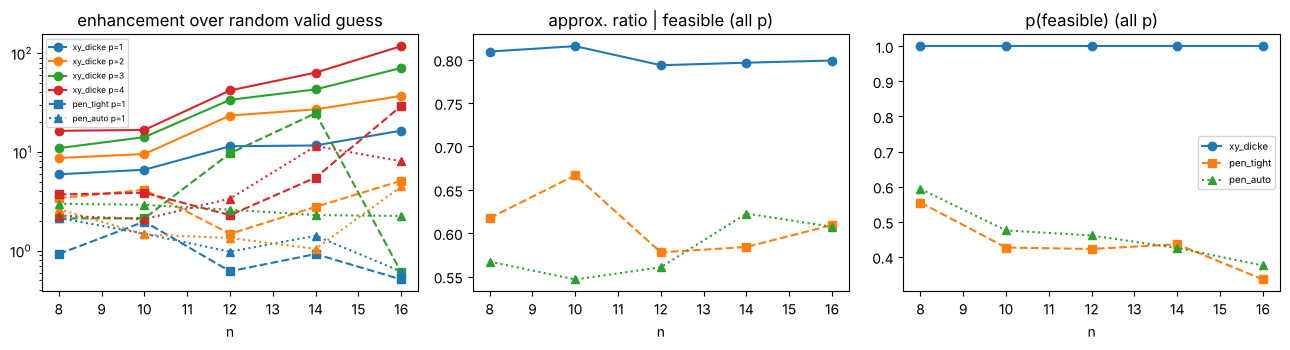

In [2]:
t=sc.groupby(['n','p','method']).agg(enh=('enhancement',f),p_feas=('p_feas','mean'),ratio=('ratio_cond','mean'),nfev=('nfev','mean')).round(3)
display(t.unstack('method')['enh'])
fig,ax=plt.subplots(1,3,figsize=(13,3.6))
for m,mk in [('xy_dicke','o-'),('pen_tight','s--'),('pen_auto','^:')]:
    for p,col in zip([1,2,3,4],['C0','C1','C2','C3']):
        d=sc[(sc.method==m)&(sc.p==p)].groupby('n')
        ax[0].plot(d.enhancement.mean(),mk,color=col,label=f'{m} p={p}' if m=='xy_dicke' or p==1 else None)
    d=sc[sc.method==m].groupby('n')
    ax[1].plot(d.ratio_cond.mean(),mk,label=m); ax[2].plot(d.p_feas.mean(),mk,label=m)
ax[0].set_yscale('log'); ax[0].set_title('enhancement over random valid guess'); ax[0].set_xlabel('n')
ax[1].set_title('approx. ratio | feasible (all p)'); ax[2].set_title('p(feasible) (all p)')
for a in ax: a.set_xlabel('n')
ax[0].legend(fontsize=6); ax[2].legend(fontsize=7); plt.tight_layout(); plt.savefig('results/scaling.png',dpi=130)

In [3]:
rows=[]
for (n,p),g in sc.groupby(['n','p']):
    pv=g.pivot(index='month',columns='method',values='enhancement')
    for other in ['pen_tight','pen_auto']:
        r=pv.xy_dicke/pv[other]
        rows.append(dict(n=n,p=p,vs=other,median_ratio=np.median(r),xy_better=(r>1).mean(),wilcoxon_p=wilcoxon(pv.xy_dicke-pv[other]).pvalue))
paired=pd.DataFrame(rows); display(paired.pivot_table(index=['n','p'],columns='vs',values=['median_ratio','xy_better']).round(2))
g=paired.groupby('n').median_ratio.median(); slope=np.polyfit(g.index,np.log(g.values),1)[0]
print(f'median (XY / best penalty) enhancement ratio vs n: {g.round(2).to_dict()}; log-slope {slope:+.3f} per qubit')

median_ratio           xy_better          
vs       pen_auto pen_tight  pen_auto pen_tight
n  p                                           
8  1         7.74      7.87      0.92      0.92
   2         8.03      5.26      0.83      0.75
   3         8.08      8.01      0.92      1.00
   4         6.40     13.09      0.92      0.83
10 1        10.29      5.79      0.92      0.92
   2        45.85      3.36      0.92      0.83
   3        32.63     22.43      0.92      0.92
   4        10.70     13.07      0.92      0.75
12 1        23.90     34.90      1.00      1.00
   2        17.33     25.53      1.00      1.00
   3        53.68     38.36      1.00      0.83
   4        14.53     30.62      0.92      0.92
14 1        24.24     26.60      0.92      1.00
   2        35.28     21.32      1.00      0.92
   3        38.89     25.61      0.92      0.92
   4        19.66     33.64      1.00      0.92
16 1        20.52     71.18      1.00      1.00
   2        25.77     40.64      1.00      1.00
   3       159.08     82.28      0.92      1.00
   4       116.38     29.30      0.92      0.92

median (XY / best penalty) enhancement ratio vs n: {8: 7.94, 10: 11.89, 12: 28.08, 14: 26.11, 16: 55.91}; log-slope +0.235 per qubit


Only 12 months per (n, p) cell, so the per-cell Wilcoxon tests have low power (minimum attainable p ≈ 5·10⁻⁴). Read the trend across n, not single cells.

## 2. Robustness at n = 12, p = 2 (46 months, every third month 2016–2026, 5 restarts)

In [4]:
rb['config']=rb.apply(lambda r:f"q={r.q:g}, win={int(r.win)}",axis=1)
t=rb.groupby(['config','method']).agg(enh=('enhancement',f),p_feas=('p_feas','mean')).unstack('method')
display(t)
rows=[]
for cfg,g in rb.groupby('config'):
    pv=g.pivot(index='month',columns='method',values='enhancement')
    for o in ['pen_tight','pen_auto']:
        d=pv.xy_dicke-pv[o]; rows.append(dict(config=cfg,vs=o,xy_better=(d>0).mean(),wilcoxon_p=wilcoxon(d).pvalue))
display(pd.DataFrame(rows).pivot(index='config',columns='vs'))

enh                                            \
method                  pen_auto           pen_tight              xy_dicke   
config                                                                       
q=0.5, win=12  3.88 [0.91, 9.22]  5.92 [1.28, 14.57]  18.12 [12.90, 24.13]   
q=2, win=12    2.47 [1.56, 3.62]   5.14 [2.94, 7.75]  16.64 [11.79, 22.20]   
q=2, win=24    2.57 [1.32, 4.60]   2.33 [1.42, 3.39]   12.14 [8.78, 16.18]   
q=2, win=6     2.99 [1.63, 4.59]   5.05 [3.11, 7.46]  16.55 [11.85, 21.98]   
q=8, win=12    1.67 [1.10, 2.34]   1.55 [1.07, 2.13]   11.75 [8.80, 15.13]   

                 p_feas                     
method         pen_auto pen_tight xy_dicke  
config                                      
q=0.5, win=12  0.545439  0.519773      1.0  
q=2, win=12    0.534842  0.531793      1.0  
q=2, win=24    0.544390  0.506191      1.0  
q=2, win=6     0.537676  0.504223      1.0  
q=8, win=12    0.488978  0.460457      1.0

xy_better              wilcoxon_p              
vs             pen_auto pen_tight      pen_auto     pen_tight
config                                                       
q=0.5, win=12  0.906977  0.883721  3.969240e-08  3.457612e-07
q=2, win=12    0.837209  0.744186  1.461990e-08  1.933492e-04
q=2, win=24    0.883721  0.883721  8.214397e-08  3.366949e-09
q=2, win=6     0.860465  0.767442  6.700088e-08  3.848125e-05
q=8, win=12    0.906977  0.906977  7.305516e-10  2.954266e-09

### Penalty scan: is there any P for which penalty QAOA catches up?

,enh,p_feas,ratio
factor,,,
0.25,1.367,0.492,0.602
0.5,1.737,0.531,0.588
1.0,5.144,0.532,0.647
2.0,3.711,0.510,0.650
4.0,3.138,0.510,0.569
8.0,1.804,0.526,0.553
16.0,2.246,0.539,0.575
qiskit auto (median factor 5.5),2.465,0.535,0.624


xy_dicke enhancement on the same months: 16.64; best penalty factor reaches 5.14


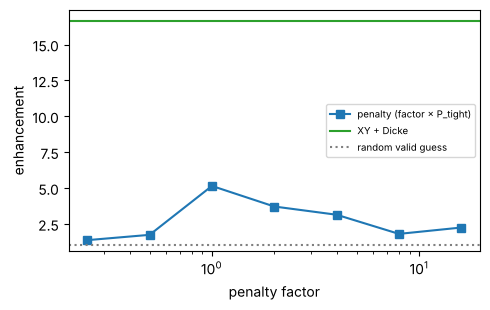

In [5]:
base=rb[(rb.q==2)&(rb.win==12)]
tight=base[base.method=='pen_tight'].assign(method='pen_1')
pgx=pd.concat([pg,tight]); pgx['factor']=pgx.method.str.replace('pen_','').astype(float)
s=pgx.groupby('factor').agg(enh=('enhancement','mean'),p_feas=('p_feas','mean'),ratio=('ratio_cond','mean'))
s.loc['qiskit auto (median factor %.1f)'%(base[base.method=='pen_auto'].P.median()/tight.P.median())]=base[base.method=='pen_auto'][['enhancement','p_feas','ratio_cond']].mean().values
display(s.round(3)); xy=base[base.method=='xy_dicke'].enhancement.mean()
print(f'xy_dicke enhancement on the same months: {xy:.2f}; best penalty factor reaches {s.enh.max():.2f}')
fig,ax=plt.subplots(figsize=(5,3.2)); ss=s.iloc[:-1]
ax.semilogx(ss.index.astype(float),ss.enh,'s-',label='penalty (factor × P_tight)'); ax.axhline(xy,color='C2',label='XY + Dicke'); ax.axhline(1,color='gray',ls=':',label='random valid guess')
ax.set_xlabel('penalty factor'); ax.set_ylabel('enhancement'); ax.legend(fontsize=7); plt.tight_layout(); plt.savefig('results/penalty_scan.png',dpi=130)

## 3. Conclusions (printed from the numbers)

In [6]:
e=sc.groupby(['n','method']).enhancement.mean().unstack()
for n in e.index: print(f"n={n:2d}: enhancement XY {e.loc[n,'xy_dicke']:.1f} | pen_tight {e.loc[n,'pen_tight']:.1f} | pen_auto {e.loc[n,'pen_auto']:.1f}")
w=pd.DataFrame(rows)
print(f"Robustness: XY beats both penalties in {w.xy_better.min():.0%}–{w.xy_better.max():.0%} of months across the 5 (q, window) settings; largest Wilcoxon p = {w.wilcoxon_p.max():.1e}.")
print('Limits: exact simulation only up to 16 qubits; 12 months per scaling cell; p ≤ 4; L-BFGS-B with 3–5 restarts may under-train deep circuits equally for all methods.')

n= 8: enhancement XY 10.5 | pen_tight 2.5 | pen_auto 2.5
n=10: enhancement XY 11.7 | pen_tight 3.0 | pen_auto 2.0
n=12: enhancement XY 27.6 | pen_tight 3.5 | pen_auto 2.1
n=14: enhancement XY 36.2 | pen_tight 8.4 | pen_auto 4.0
n=16: enhancement XY 60.4 | pen_tight 8.8 | pen_auto 3.8
Robustness: XY beats both penalties in 74%–91% of months across the 5 (q, window) settings; largest Wilcoxon p = 1.9e-04.
Limits: exact simulation only up to 16 qubits; 12 months per scaling cell; p ≤ 4; L-BFGS-B with 3–5 restarts may under-train deep circuits equally for all methods.
